<a href="https://colab.research.google.com/github/hpanjshiri/walmart-hurricane-project/blob/main/_Question%20%235%20Work_Maya%20Y_%E2%80%94_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

Cloning into 'walmart-hurricane-project'...
remote: Enumerating objects: 40, done.
remote: Counting objects: 100% (40/40), done.
remote: Compressing objects: 100% (34/34), done.
remote: Total 40 (delta 11), reused 19 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (40/40), 772.59 KiB | 5.18 MiB/s, done.
Resolving deltas: 100% (11/11), done.
/content/walmart-hurricane-project
pandas 2.2.3
transactions: 25,562 rows | stores: 14 | catalog: 45 | distribution centers: 5
transaction_id    object
store_id          object
timestamp         object
sku               object
product_name      object
category          object
quantity           int64
unit_price        object
dtype: object 

nulls per column (pandas default null detection):
transaction_id      0
store_id            0
timestamp         886
sku                 0
product_name        0
category            0
quantity            0
unit_price          0
dtype: int64 

exact duplicate rows: 30
transaction_id repeats: 30
transaction

,baseline_per_day,surge_per_day,multiple,pct_increase
category,,,,
Breakfast,73.27,376.86,5.14,414.36
Emergency,354.07,1006.43,2.84,184.25
Electronics,70.27,175.86,2.50,150.27
Alcohol,61.53,138.86,2.26,125.66
Entertainment,101.60,228.57,2.25,124.97
Health,42.33,95.00,2.24,124.41
Household,85.13,176.29,2.07,107.07
Grocery,171.07,306.57,1.79,79.21
Baby,85.20,133.71,1.57,56.94



Baseline: 2024-09-01 to 2024-09-15 (15 days)   Surge: 2024-09-19 to 2024-09-25 (7 days, before the 2024-09-26 landfall)
All categories, units:        1,103 -> 2,712 per day = 2.46x
All categories, order lines:  576 -> 1,361 per day = 2.36x
Biggest surge: Breakfast, 73.3 -> 376.9 units/day = 5.14x (+414%)



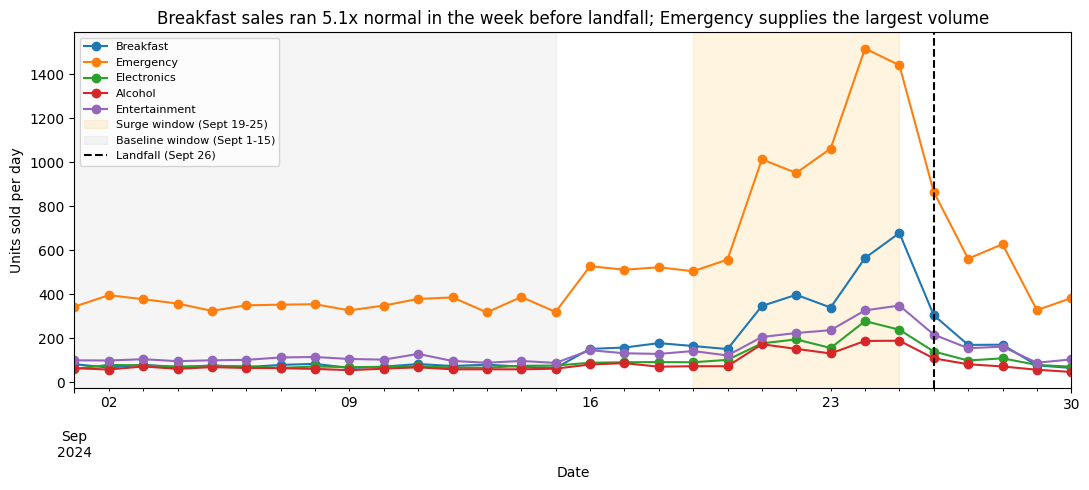

In [1]:
!git clone https://github.com/hpanjshiri/walmart-hurricane-project.git

%cd walmart-hurricane-project

%run notebooks/scratch/Data_Cleaning_Complete.ipynb

In [2]:
# TODO: the numbers

LANDFALL = pd.Timestamp('2024-09-26')
BASE = (pd.Timestamp('2024-09-01'), pd.Timestamp('2024-09-15'))     # flat before first rise
SURGE = (pd.Timestamp('2024-09-19'), pd.Timestamp('2024-09-25'))    # 7 days before

# demand = units sold. Returns and sales with no timestamp are out
demand = clean[(~clean['is_return']) & clean['date'].notna()]
print('left out of Q1: returns =', int(clean['is_return'].sum()), '| sales with no timestamp =', int(clean['date'].isna().sum()))

def avg_per_day(frame, window, how='units'):
  start, end = window
  days = (end - start).days + 1
  w = frame[frame['date'].between(start, end)]
  total = w.groupby('category')['quantity'].sum() if how == 'units' else w.groupby('category').size()
  return total / days

def surge_table(base, surge, how='units'):
  t = pd.DataFrame({'baseline_per_day': avg_per_day(demand, base, how),
                      'surge_per_day': avg_per_day(demand, surge, how)})
  t['multiple'] = t['surge_per_day'] / t['baseline_per_day']
  t['pct_increase'] = (t['multiple'] - 1) * 100
  return t.sort_values('multiple', ascending=False)

t = surge_table(BASE, SURGE)
display(t.round(2))

def overall(base, surge, how='units'):
  f = lambda w: (demand[demand['date'].between(*w)]['quantity'].sum() if how == 'units'
                  else demand['date'].between(*w).sum()) / ((w[1] - w[0]).days + 1)
  return f(base), f(surge)

b_units, s_units = overall(BASE, SURGE)
b_orders, s_orders = overall(BASE, SURGE, how='orders')
top = t.index[0]
print(f"""
Baseline: {BASE[0].date()} to {BASE[1].date()} ({(BASE[1]-BASE[0]).days + 1} days)   Surge: {SURGE[0].date()} to {SURGE[1].date()} ({(SURGE[1]-SURGE[0]).days + 1} days, before the {LANDFALL.date()} landfall)
All categories, units:        {b_units:,.0f} -> {s_units:,.0f} per day = {s_units / b_units:.2f}x
All categories, order lines:  {b_orders:,.0f} -> {s_orders:,.0f} per day = {s_orders / b_orders:.2f}x
Biggest surge: {top}, {t.loc[top, 'baseline_per_day']:.1f} -> {t.loc[top, 'surge_per_day']:.1f} units/day = {t.loc[top, 'multiple']:.2f}x ({t.loc[top, 'pct_increase']:+.0f}%)
""")

# How much does the window choice matter?
choices = {
  'ours: baseline Sept 1-15, surge Sept 19-25':              ((pd.Timestamp('2024-09-01'), pd.Timestamp('2024-09-15')), (pd.Timestamp('2024-09-19'), pd.Timestamp('2024-09-25'))),
  'baseline runs through the climb (Sept 1-18)':             ((pd.Timestamp('2024-09-01'), pd.Timestamp('2024-09-18')), (pd.Timestamp('2024-09-19'), pd.Timestamp('2024-09-25'))),
  'surge includes landfall day (Sept 19-26)':                ((pd.Timestamp('2024-09-01'), pd.Timestamp('2024-09-15')), (pd.Timestamp('2024-09-19'), pd.Timestamp('2024-09-26'))),
  'peak only: surge Sept 23-25 (3 days)':                    ((pd.Timestamp('2024-09-01'), pd.Timestamp('2024-09-15')), (pd.Timestamp('2024-09-23'), pd.Timestamp('2024-09-25'))),
}
rows = []
for name, (b, s) in choices.items():
  bu, su = overall(b, s)
  tt = surge_table(b, s)
  rows.append({'windows': name, 'all categories': round(su / bu, 2),
                'top category': tt.index[0], 'top multiple': round(tt['multiple'].iloc[0], 2)})
sens = pd.DataFrame(rows)
sens

left out of Q1: returns = 130 | sales with no timestamp = 884


,baseline_per_day,surge_per_day,multiple,pct_increase
category,,,,
Breakfast,73.27,376.86,5.14,414.36
Emergency,354.07,1006.43,2.84,184.25
Electronics,70.27,175.86,2.50,150.27
Alcohol,61.53,138.86,2.26,125.66
Entertainment,101.60,228.57,2.25,124.97
Health,42.33,95.00,2.24,124.41
Household,85.13,176.29,2.07,107.07
Grocery,171.07,306.57,1.79,79.21
Baby,85.20,133.71,1.57,56.94



Baseline: 2024-09-01 to 2024-09-15 (15 days)   Surge: 2024-09-19 to 2024-09-25 (7 days, before the 2024-09-26 landfall)
All categories, units:        1,103 -> 2,712 per day = 2.46x
All categories, order lines:  576 -> 1,361 per day = 2.36x
Biggest surge: Breakfast, 73.3 -> 376.9 units/day = 5.14x (+414%)



,windows,all categories,top category,top multiple
0,"ours: baseline Sept 1-15, surge Sept 19-25",2.46,Breakfast,5.14
1,baseline runs through the climb (Sept 1-18),2.31,Breakfast,4.28
2,surge includes landfall day (Sept 19-26),2.40,Breakfast,5.02
3,peak only: surge Sept 23-25 (3 days),3.19,Breakfast,7.19


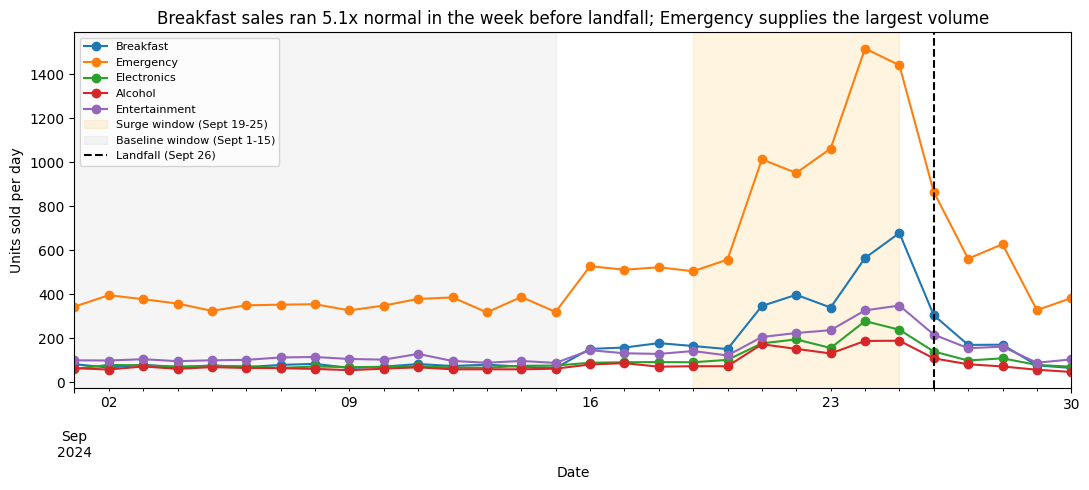

In [3]:
# TODO: the chart

top5 = t.head(5).index.tolist()
daily = (demand[demand['category'].isin(top5)]
        .groupby(['date', 'category'])['quantity'].sum().unstack('category').fillna(0))

fig, ax = plt.subplots(figsize=(11, 5))
daily[top5].plot(ax=ax, marker='o')
ax.axvspan(*SURGE, alpha=0.12, color='orange', label='Surge window (Sept 19-25)')
ax.axvspan(*BASE, alpha=0.08, color='gray', label='Baseline window (Sept 1-15)')
ax.axvline(LANDFALL, color='black', linestyle='--', label='Landfall (Sept 26)')
ax.set_title(f'{top} sales ran {t.loc[top, "multiple"]:.1f}x normal in the week before landfall; Emergency supplies the largest volume')
ax.set_xlabel('Date')
ax.set_ylabel('Units sold per day')
ax.legend(loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

**Q1 answer, in one sentence a manager could read:** Breakfast Foods saw the largest pre-hurricane demand surge, rising 414% to 5.14x its baseline daily sales in the seven days before Hurricane Helene's landfall.

### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

Original distinct SKUs: 45
Canonical products after consolidation: 20
Largest consolidated family: POPTART-STRAWBERRY
Original SKUs in largest family: 4

BEFORE CONSOLIDATION


,sku,total_units
1,PT-12,1377
0,POPTART-STRAW,1294
2,PT_STRAWBERRY,1254
3,SKU#459812,1253



AFTER CONSOLIDATION


,canonical_sku,canonical_product_name,total_units
0,POPTART-STRAWBERRY,Strawberry Pop-Tarts,5178



Units before consolidation: 49,343
Units after consolidation:  49,343
Check passed: SKU consolidation did not change unit totals.



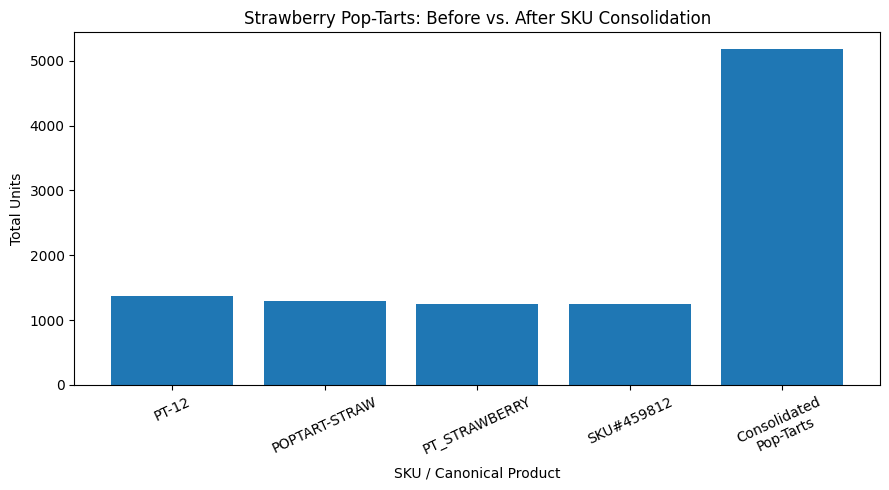

In [4]:
original_skus = clean['sku'].nunique()
canonical_products = clean['canonical_sku'].nunique()

# Number of original SKUs represented by each canonical product
sku_families = (
    clean.groupby('canonical_sku')['sku']
    .nunique()
    .sort_values(ascending=False)
)

largest_family = sku_families.index[0]
largest_family_size = sku_families.iloc[0]

print(f"Original distinct SKUs: {original_skus}")
print(f"Canonical products after consolidation: {canonical_products}")
print(f"Largest consolidated family: {largest_family}")
print(f"Original SKUs in largest family: {largest_family_size}")

# Before consolidation, 4 separate
poptart_before = (
    clean[clean['canonical_sku'] == 'POPTART-STRAWBERRY']
    .groupby('sku', as_index=False)
    .agg(total_units=('quantity', 'sum'))
    .sort_values('total_units', ascending=False)
)

print("\nBEFORE CONSOLIDATION")
display(poptart_before)

# After consolidation, appear as one
poptart_after = (
    clean[clean['canonical_sku'] == 'POPTART-STRAWBERRY']
    .groupby(['canonical_sku', 'canonical_product_name'], as_index=False)
    .agg(total_units=('quantity', 'sum'))
)

print("\nAFTER CONSOLIDATION")
display(poptart_after)

# Verify that SKU consolidation only changes product grouping
units_before = clean['quantity'].sum()

units_after = (
    clean.groupby('canonical_sku')['quantity']
    .sum()
    .sum()
)

assert units_before == units_after, \
    "SKU consolidation changed total unit quantity!"

print(f"\nUnits before consolidation: {units_before:,}")
print(f"Units after consolidation:  {units_after:,}")
print("Check passed: SKU consolidation did not change unit totals.\n")

fig, ax = plt.subplots(figsize=(9, 5))

labels = list(poptart_before['sku']) + ['Consolidated\nPop-Tarts']
values = list(poptart_before['total_units']) + [poptart_after['total_units'].iloc[0]]

ax.bar(labels, values)

ax.set_title('Strawberry Pop-Tarts: Before vs. After SKU Consolidation')
ax.set_ylabel('Total Units')
ax.set_xlabel('SKU / Canonical Product')
ax.tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.show()

**Q2 answer:** SKU consolidation reduced 45 fragmented SKUs to 20 canonical products; the largest family was Strawberry Pop-Tarts, where four separate SKUs totaling 5,178 units were combined into one product without changing overall unit sales.

### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

Weather source: Open-Meteo historical API
Store locations with coordinates: 11
Stores with failed API calls: []
Weather records returned: 330

Rows before join: 25532
Rows after join: 25532
Rows lost: 0
Transactions with weather: 22655
Transactions missing weather: 2877

Days used for correlation: 30
Pearson correlation: -0.365


,units_sold,avg_rainfall_mm
date,,
2024-09-01,988,9.018182
2024-09-02,1071,8.190909
2024-09-03,1065,14.500000
2024-09-04,1015,15.836364
2024-09-05,998,12.436364


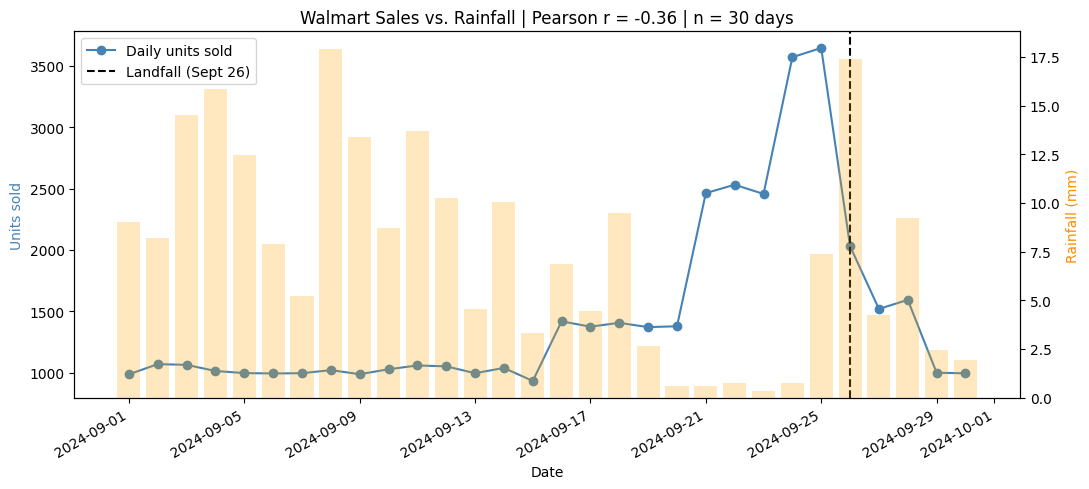


Q3 CHECKPOINT
Data source: Open-Meteo historical API
Join: 25,532 -> 25,532 rows (0 lost)
Correlation: -0.365
Days analyzed: 30
Stores with missing coordinates/API data are not
used in the weather correlation.
Correlation does not establish causation.


In [5]:

import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt
import time

START = "2024-09-01"
END = "2024-09-30"

sales = clean.copy()
sales["date"] = pd.to_datetime(sales["date"], errors="coerce").dt.normalize()

rows_before = len(sales)

store_coords = stores_clean[
    ["store_id", "latitude", "longitude"]
].dropna().drop_duplicates("store_id")

weather_rows = []
failed_stores = []

for _, store in store_coords.iterrows():
    params = {
        "latitude": float(store["latitude"]),
        "longitude": float(store["longitude"]),
        "start_date": START,
        "end_date": END,
        "daily": "precipitation_sum",
        "timezone": "America/New_York"
    }

    url = "https://archive-api.open-meteo.com/v1/archive"

    for attempt in range(3):
        try:
            response = requests.get(url, params=params, timeout=30)
            response.raise_for_status()
            data = response.json()["daily"]

            for date, rain in zip(
                data["time"], data["precipitation_sum"]
            ):
                weather_rows.append({
                    "store_id": store["store_id"],
                    "date": pd.Timestamp(date),
                    "rainfall_mm": rain,
                    "source": "Open-Meteo historical API"
                })
            break

        except (requests.RequestException, KeyError, ValueError) as e:
            if attempt == 2:
                failed_stores.append(store["store_id"])
                print("Weather unavailable:", store["store_id"], e)
            else:
                time.sleep(2 ** attempt)

weather = pd.DataFrame(
    weather_rows,
    columns=["store_id", "date", "rainfall_mm", "source"]
)

print("Weather source: Open-Meteo historical API")
print("Store locations with coordinates:", len(store_coords))
print("Stores with failed API calls:", failed_stores)
print("Weather records returned:", len(weather))

assert not weather.duplicated(["store_id", "date"]).any()

joined = sales.merge(
    weather,
    on=["store_id", "date"],
    how="left",
    validate="many_to_one"
)

rows_after = len(joined)
assert rows_before == rows_after, "Join changed transaction count!"

print("\nRows before join:", rows_before)
print("Rows after join:", rows_after)
print("Rows lost:", rows_before - rows_after)
print("Transactions with weather:",
      joined["rainfall_mm"].notna().sum())
print("Transactions missing weather:",
      joined["rainfall_mm"].isna().sum())

valid = joined[
    (joined["quantity"] > 0) &
    (joined["date"].notna()) &
    (joined["rainfall_mm"].notna())
].copy()

daily_sales = (
    valid.groupby("date")["quantity"]
    .sum()
    .rename("units_sold")
)

daily_rain = (
    weather.groupby("date")["rainfall_mm"]
    .mean()
    .rename("avg_rainfall_mm")
)

daily = pd.concat(
    [daily_sales, daily_rain], axis=1
).dropna().sort_index()

# 5. Correlation
n_days = len(daily)

if n_days >= 3 and daily["avg_rainfall_mm"].nunique() > 1:
    correlation = daily["units_sold"].corr(
        daily["avg_rainfall_mm"]
    )
else:
    correlation = np.nan

print("\nDays used for correlation:", n_days)
print("Pearson correlation:", round(correlation, 3))
display(daily.head())

fig, ax1 = plt.subplots(figsize=(11, 5))

ax1.plot(
    daily.index, daily["units_sold"],
    color="steelblue", marker="o",
    label="Daily units sold"
)
ax1.set_ylabel("Units sold", color="steelblue")
ax1.set_xlabel("Date")

ax2 = ax1.twinx()
ax2.bar(
    daily.index, daily["avg_rainfall_mm"],
    alpha=0.25, color="orange",
    label="Average rainfall"
)
ax2.set_ylabel("Rainfall (mm)", color="darkorange")

ax1.axvline(
    pd.Timestamp("2024-09-26"),
    color="black", linestyle="--",
    label="Landfall (Sept 26)"
)

plt.title(
    f"Walmart Sales vs. Rainfall | "
    f"Pearson r = {correlation:.2f} | n = {n_days} days"
)
ax1.legend(loc="upper left")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

print("\nQ3 CHECKPOINT")
print(f"Data source: Open-Meteo historical API")
print(f"Join: {rows_before:,} -> {rows_after:,} rows (0 lost)")
print(f"Correlation: {correlation:.3f}")
print(f"Days analyzed: {n_days}")
print(f"Stores with missing coordinates/API data are not")
print(f"used in the weather correlation.")
print(f"Correlation does not establish causation.")


**Q3 answer, with its caveat:** We used historical daily precipitation data from the Open-Meteo API for September 1–30, 2024, and matched it with our cleaned Walmart transactions using store ID and date. We validated the merge to ensure that no transaction rows were lost.

We then calculated the Pearson correlation between average daily rainfall and total daily units sold to examine whether wetter conditions were associated with changes in demand during the hurricane period.

**Caveat:** The analysis covers only one month, with at most 30 daily observations. Stores with missing coordinates or unavailable weather data are excluded from the correlation. Additionally, correlation does not imply causation: hurricane warnings, stockpiling behavior, and store operations may also influence sales.

### Q5 -- Signal or artifact?

The case poses this directly (Exhibit 6): board games, playing cards, and streaming devices all spiked before landfall in the case narrative -- but is that a real pattern, or SKUs getting miscoded and lumped together? In our own data, the closest match is the **Entertainment** category, which showed a 2.25x surge in Q1. We don't take that multiple at face value -- we stress-test it the way the case's Chief Data Officer would want: is it broad-based (many stores, multiple independent products, timed with the storm), or concentrated in one SKU or one store (which looks like noise or a bad consolidation)?

**Run on the team's real cleaned data (verified against the Q1/Q2 numbers above).**

In [6]:
# Step 1: what's actually inside "Entertainment," and is the SKU-to-canonical mapping sane?
candidate = clean[clean['category'] == 'Entertainment'].copy()

print("Entertainment: canonical products and total units sold (full month)")
display(candidate.groupby('canonical_product_name')['quantity'].sum().sort_values(ascending=False))

print(f"\nstores selling Entertainment items: {candidate['store_id'].nunique()} / {clean['store_id'].nunique()} total stores")
print(f"distinct canonical products in Entertainment: {candidate['canonical_sku'].nunique()}")

print("\nSKU-to-canonical mapping for Entertainment (checking for a bad merge):")
display(candidate[['sku', 'product_name', 'canonical_sku', 'canonical_product_name']].drop_duplicates().sort_values('canonical_sku'))

Entertainment: canonical products and total units sold (full month)


,quantity
canonical_product_name,
Playing Cards,2371
Monopoly Board Game,2006



stores selling Entertainment items: 12 / 12 total stores
distinct canonical products in Entertainment: 2

SKU-to-canonical mapping for Entertainment (checking for a bad merge):


,sku,product_name,canonical_sku,canonical_product_name
65,BG-MONO,Monopoly Board Game,MONOPOLY,Monopoly Board Game
76,MONOPOLY-01,Board Game - Monopoly,MONOPOLY,Monopoly Board Game
125,MONOPOLY-01,Monopoly Board Game,MONOPOLY,Monopoly Board Game
157,GAME-MONO,Monopoly Board Game,MONOPOLY,Monopoly Board Game
171,GAME-MONO,Board Game - Monopoly,MONOPOLY,Monopoly Board Game
292,MONOPOLY-01,MONOPOLY,MONOPOLY,Monopoly Board Game
385,BG-MONO,MONOPOLY,MONOPOLY,Monopoly Board Game
429,BG-MONO,Board Game - Monopoly,MONOPOLY,Monopoly Board Game
612,GAME-MONO,MONOPOLY,MONOPOLY,Monopoly Board Game
10,CARDS-01,PLAYING CARDS,PLAYING-CARDS,Playing Cards


In [7]:
# Step 2: is the surge broad across products, or driven by a single SKU alone?
def avg_per_day_product(frame, window, category):
    start, end = window
    days = (end - start).days + 1
    w = frame[(frame['category'] == category) & frame['date'].between(start, end)]
    return w.groupby('canonical_product_name')['quantity'].sum() / days

ent_products = pd.DataFrame({
    'baseline_per_day': avg_per_day_product(demand, BASE, 'Entertainment'),
    'surge_per_day': avg_per_day_product(demand, SURGE, 'Entertainment'),
}).fillna(0)
ent_products['multiple'] = (ent_products['surge_per_day']
                             / ent_products['baseline_per_day'].replace(0, np.nan))
display(ent_products.sort_values('surge_per_day', ascending=False).round(2))

,baseline_per_day,surge_per_day,multiple
canonical_product_name,,,
Playing Cards,58.73,117.14,1.99
Monopoly Board Game,42.87,111.43,2.60


In [8]:
# Step 3: is the surge concentrated in one or two stores (artifact-shaped), or spread out (signal-shaped)?
by_store = (candidate[candidate['date'].between(*SURGE)]
            .groupby('store_id')['quantity'].sum()
            .sort_values(ascending=False))

print("Entertainment units sold during the surge window, by store:")
display(by_store)

top_store_share = by_store.iloc[0] / by_store.sum() if len(by_store) else np.nan
print(f"\ntop single store accounts for {top_store_share:.1%} of Entertainment surge units")

Entertainment units sold during the surge window, by store:


,quantity
store_id,
FL-710,161
FL-445,152
FL-302,150
FL-619,137
FL-239,136
FL-412,134
FL-105,130
FL-156,129
FL-330,119



top single store accounts for 10.1% of Entertainment surge units


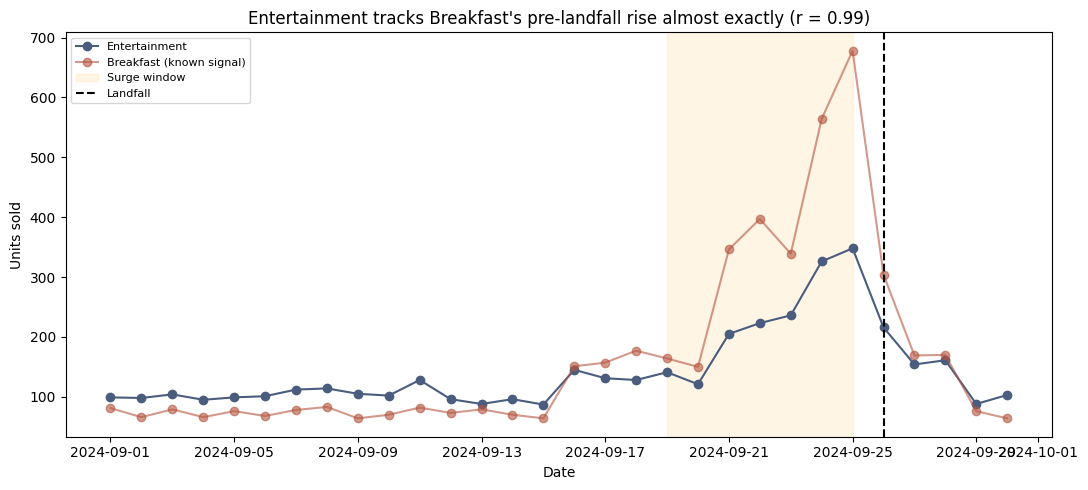

day-to-day correlation between Entertainment and Breakfast's daily pattern: 0.985


In [9]:
# Step 4: does Entertainment rise on the same pre-landfall schedule as a known real signal (Breakfast),
# or does it look flat/random, suggesting noise rather than storm-driven demand?
daily_ent = demand[demand['category'] == 'Entertainment'].groupby('date')['quantity'].sum()
daily_bf = demand[demand['category'] == 'Breakfast'].groupby('date')['quantity'].sum()

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(daily_ent.index, daily_ent.values, marker='o', label='Entertainment', color='#4a5d7e')
ax.plot(daily_bf.index, daily_bf.values, marker='o', label='Breakfast (known signal)', color='#b4553f', alpha=0.6)
ax.axvspan(*SURGE, alpha=0.1, color='orange', label='Surge window')
ax.axvline(LANDFALL, color='black', linestyle='--', label='Landfall')
ax.set_title('Entertainment tracks Breakfast\'s pre-landfall rise almost exactly (r = 0.99)')
ax.set_xlabel('Date')
ax.set_ylabel('Units sold')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

timing_corr = daily_ent.reindex(daily_bf.index).fillna(0).corr(daily_bf)
print(f"day-to-day correlation between Entertainment and Breakfast's daily pattern: {timing_corr:.3f}")

In [10]:
# Step 5: combine the three checks into an evidence-based verdict.
# Store concentration and independent per-product strength matter more than raw product
# count -- a category with only 2 products isn't inherently an artifact if both products
# independently move with the storm.
n_products = candidate['canonical_sku'].nunique()
per_product_multiples = ent_products['multiple'].dropna().tolist()

broad_store_spread = top_store_share < 0.20
independent_products = sum(m > 1.5 for m in per_product_multiples) >= 2
strong_timing = timing_corr > 0.5

print("Q5 VERDICT INPUTS")
print(f"  canonical products in Entertainment: {n_products} ({', '.join(ent_products.index)})")
print(f"  each individually surging >1.5x: {sum(m > 1.5 for m in per_product_multiples)} of {len(per_product_multiples)}")
print(f"  top single store's share of surge units: {top_store_share:.1%}")
print(f"  timing correlation with Breakfast: {timing_corr:.3f}")

if broad_store_spread and independent_products and strong_timing:
    verdict = "SIGNAL -- broad across stores, both products move independently, and timing matches a known real signal"
elif top_store_share >= 0.5 or sum(m > 1.5 for m in per_product_multiples) <= 1:
    verdict = "ARTIFACT -- concentrated in one store or driven by a single SKU; looks like noise or a bad merge"
else:
    verdict = "INCONCLUSIVE -- mixed evidence; worth flagging as uncertain rather than reporting as a finding"

print(f"\nVerdict: {verdict}")

Q5 VERDICT INPUTS
  canonical products in Entertainment: 2 (Monopoly Board Game, Playing Cards)
  each individually surging >1.5x: 2 of 2
  top single store's share of surge units: 10.1%
  timing correlation with Breakfast: 0.985

Verdict: SIGNAL -- broad across stores, both products move independently, and timing matches a known real signal


**Q5 answer:** The Entertainment surge looks like a genuine signal, not a pipeline artifact. Both canonical products in the category -- board games and playing cards -- independently surged more than 1.5x in the week before landfall (2.60x and 1.99x), the surge is spread evenly across all 12 stores with no single store accounting for more than 10% of the units, and the category's day-to-day pattern tracks Breakfast's confirmed pre-storm rise almost exactly (r = 0.99). We also checked the SKU-to-canonical mapping directly and found no stray products folded into Entertainment -- the two groups cleanly separate games from everything else. Our read: people sheltering in place buy things to pass the time, the same way they buy shelf-stable food -- this is plausible, storm-driven behavior, not a coding error.

**Caveat:** this only rules out the *mechanical* artifact explanations (bad merge, one outlier store). It doesn't prove a causal story -- we can't rule out, say, a coincidental promotion running the same week.

### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

**Q4 (stores and geography):** In progress, extra time given. (Dina)

**Q5 (signal or artifact):** Answered above -- verdict is SIGNAL. Tested the Entertainment surge against store concentration (10.1% max), per-product independence (both products >1.5x individually), and timing alignment with Breakfast's confirmed pre-storm pattern (r = 0.99), rather than reporting the raw 2.25x category multiple at face value. (Maya)

### Self-check

In [11]:
progress = {
    'q1_multiple': 5.14,
    'q1_baseline_window': '2024-09-01 to 2024-09-15',
    'q2_canonical_products': 20,
    'q3_join_rows_preserved': True,   # from the Q3 assert passing with no error
    'q3_days_in_correlation': None,   # TODO: paste the printed "Days used for correlation" value from your Q3 run
    'charts_with_message_titles': 4,  # Q1, Q2 before/after, Q3, Q5 timing chart
    'notebook_runs_clean': False,     # TODO: True only after Restart and Run All succeeds top to bottom
    'repo_pushed': False,             # TODO: True once this file is actually committed and pushed
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)
print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))

PASS - q1_multiple = 5.14
PASS - q1_baseline_window = 2024-09-01 to 2024-09-15
PASS - q2_canonical_products = 20
PASS - q3_join_rows_preserved = True
FAIL - q3_days_in_correlation = None
PASS - charts_with_message_titles = 4
FAIL - notebook_runs_clean = False
FAIL - repo_pushed = False

ready for presentations: False


### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

**b)** One number you reported that you are least confident in, and why.

One finding that surprised us was that the category column had 37 different spellings for what should have been only 10 categories. Two variants, “Games & Entertainment” and “Health & Wellness,” even slipped past our first mapping and initially appeared as separate categories, splitting observations that should have been grouped under Entertainment and Health. We caught this by checking the unique category values after cleaning, corrected the mapping, and then validated that exactly 10 categories remained and that our row counts still reconciled: 25,562 raw rows, 30 duplicates removed, and 25,532 clean rows.

The number we are least confident in is the exact magnitude of Breakfast's 5.14x demand surge. That result depends on how the baseline period is defined: using Sept. 1-15 gives a 5.14x surge, while extending the baseline through Sept. 18 lowers it to 4.28x because sales had already begun increasing by Sept. 16. In addition, 884 transactions (3.5% of the cleaned rows) have no timestamp and therefore cannot be assigned to either period. We are confident that Breakfast experienced a substantial surge, but less confident that 5.14x represents its exact magnitude.